In [4]:
!pip install -q pandas scikit-learn matplotlib scipy

In [5]:
from google.colab import files

uploaded = files.upload()

Saving fitness_activity_clustering_practice.csv to fitness_activity_clustering_practice (1).csv


Dataset shape: (50, 6)


,Member_ID,Age,Resting_Heart_Rate_bpm,Sleep_Hours,Daily_Steps,Workout_Minutes_Per_Day
0,101,18,72,7.5,8200,35
1,102,21,68,6.8,6400,42
2,103,19,75,8.1,9100,28
3,104,35,82,6.2,5200,48
4,105,28,70,7.0,7000,40


K-Means evaluation:
K=2 | Inertia=59.37 | Silhouette=0.626
K=3 | Inertia=33.46 | Silhouette=0.531
K=4 | Inertia=18.52 | Silhouette=0.514
K=5 | Inertia=13.90 | Silhouette=0.497
K=6 | Inertia=10.38 | Silhouette=0.466

K-Means cluster sizes:
KMeans_Cluster
0    13
1    22
2    15
Name: count, dtype: int64

K-Means cluster averages:


,Age,Resting_Heart_Rate_bpm,Sleep_Hours,Daily_Steps,Workout_Minutes_Per_Day
KMeans_Cluster,,,,,
0,40.92,88.54,5.74,4176.92,57.15
1,23.18,69.77,7.56,8427.27,33.59
2,32.53,78.73,6.50,6080.00,45.40



Hierarchical cluster sizes:
Hierarchical_Cluster
0    27
1    12
2    11
Name: count, dtype: int64

Hierarchical cluster averages:


,Age,Resting_Heart_Rate_bpm,Sleep_Hours,Daily_Steps,Workout_Minutes_Per_Day
Hierarchical_Cluster,,,,,
0,24.41,70.63,7.43,8162.96,35.11
1,34.50,81.50,6.27,5475.00,47.92
2,41.55,89.27,5.69,4072.73,58.18


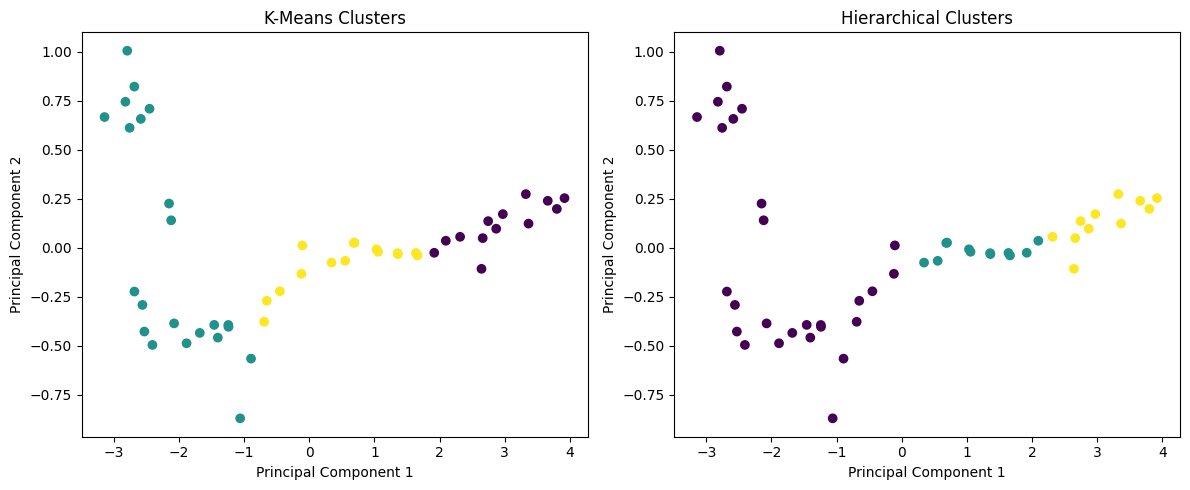

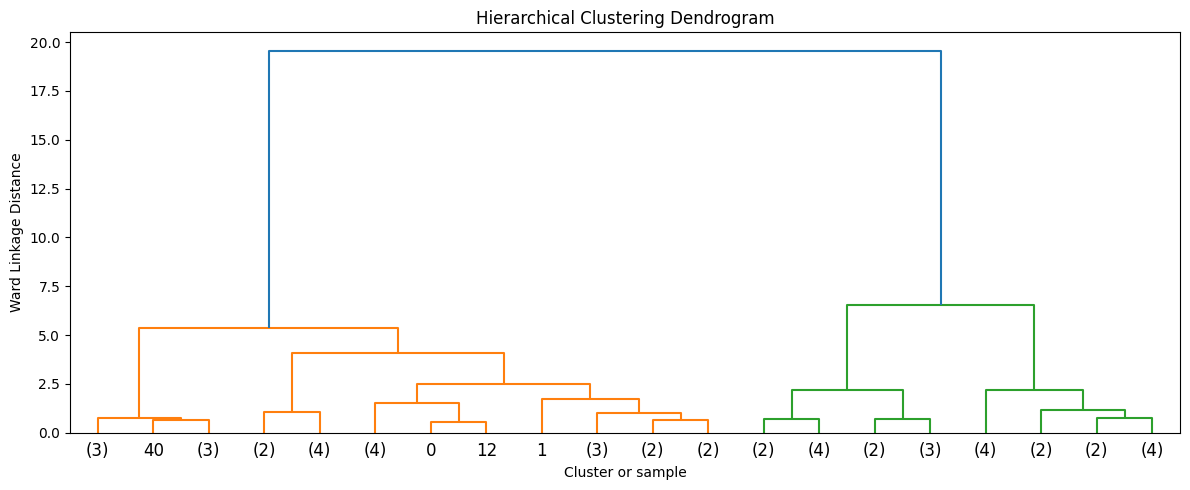

Clustering complete!
Saved: fitness_activity_clustering_results.csv


In [6]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

# 1. Load dataset
df = pd.read_csv("fitness_activity_clustering_practice.csv")

print("Dataset shape:", df.shape)
display(df.head())

# 2. Select features; exclude the member ID
features = [
    "Age",
    "Resting_Heart_Rate_bpm",
    "Sleep_Hours",
    "Daily_Steps",
    "Workout_Minutes_Per_Day"
]

X = df[features]

# 3. Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Compare K-Means models for different K values
print("K-Means evaluation:")
for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(
        f"K={k} | Inertia={model.inertia_:.2f} "
        f"| Silhouette={score:.3f}"
    )

# 5. Fit K-Means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# 6. Fit Hierarchical Clustering with 3 clusters
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

df["Hierarchical_Cluster"] = (
    hierarchical.fit_predict(X_scaled)
)

# 7. Inspect cluster sizes and averages
print("\nK-Means cluster sizes:")
print(df["KMeans_Cluster"].value_counts().sort_index())

print("\nK-Means cluster averages:")
display(
    df.groupby("KMeans_Cluster")[features]
    .mean()
    .round(2)
)

print("\nHierarchical cluster sizes:")
print(
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

print("\nHierarchical cluster averages:")
display(
    df.groupby("Hierarchical_Cluster")[features]
    .mean()
    .round(2)
)

# 8. Visualize clusters using PCA
# PCA is used for visualization only.
X_2d = PCA(n_components=2).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=df["KMeans_Cluster"]
)
axes[0].set_title("K-Means Clusters")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")

axes[1].scatter(
    X_2d[:, 0], X_2d[:, 1],
    c=df["Hierarchical_Cluster"]
)
axes[1].set_title("Hierarchical Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

# 9. Display a hierarchical dendrogram
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster or sample")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.show()

# 10. Download the clustered results
output_file = "fitness_activity_clustering_results.csv"
df.to_csv(output_file, index=False)

print("Clustering complete!")
print("Saved:", output_file)
